# 01 – Portafolio
**Lab #2 – Derivados Financieros** · Puntos 1 a 5 (proceso de creación del portafolio: 20 % + R5 y R6)

## Importar librerías

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import yfinance as yf

RAW = Path("../data/raw")
PROC = Path("../data/processed")

## Punto 1 – Análisis fundamental (R1 – 5 %)

,Precio 30/10/2026,Máx 52s,Mín 52s,Dist. al máx,Ret. precio YTD,Ret. total 1a,Ret. total 3a,Ret. total 5a
ADI,417.11,445.48,225.20,-6.4%,53.8%,81.3%,180.4%,161.4%
CSCO,104.51,130.00,71.04,-19.6%,35.7%,46.0%,118.6%,114.1%
PYPL,57.01,69.27,39.08,-17.7%,-2.3%,-15.1%,12.9%,-75.2%
^NDX,"28,384.85","31,224.47","22,953.38",-9.1%,12.4%,10.3%,98.0%,79.1%


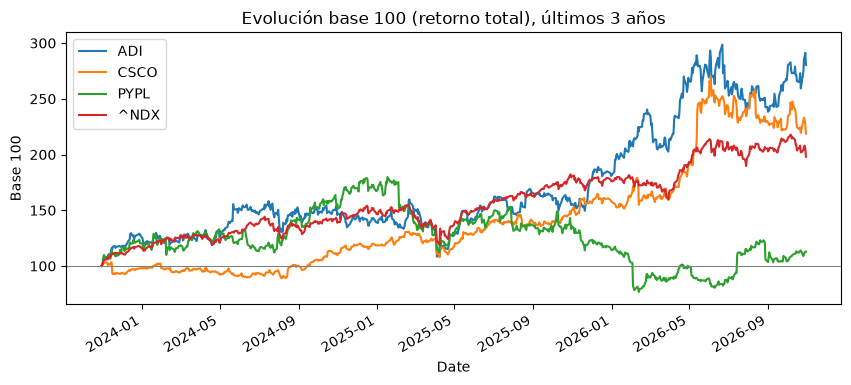

In [10]:
def leer_precios(nombre):
    df = pd.read_csv(RAW / nombre, index_col=0)                    # lee el CSV con la fecha como índice
    df = df[pd.to_datetime(df.index, errors="coerce").notna()]    # descarta filas de encabezado extra que deja yfinance
    df.index = pd.to_datetime(df.index)                           # convierte el índice a fechas
    return df.astype(float)                                       # asegura que los precios sean numéricos

close = leer_precios("close_diario.csv")      # precios sin ajustar (retorno de precio)
adj = leer_precios("adjclose_diario.csv")     # precios ajustados (retorno total)
f = close.index[-1]                           # fecha de inicio de la inversión: 30/10/2026

def ret(df, años):                                        # retorno entre hace N años y hoy
    p0 = df.loc[:f - pd.DateOffset(years=años)].iloc[-1]  # último precio disponible hace N años
    return df.iloc[-1] / p0 - 1                           # Pₜ / P₀ − 1

ult_año = close.loc[f - pd.DateOffset(years=1):]          # ventana de 52 semanas
evol = pd.DataFrame({
    "Precio 30/10/2026": close.iloc[-1],
    "Máx 52s": ult_año.max(),
    "Mín 52s": ult_año.min(),
    "Dist. al máx": close.iloc[-1] / ult_año.max() - 1,             # % por debajo del máximo
    "Ret. precio YTD": close.iloc[-1] / close.loc[:"2025-12-31"].iloc[-1] - 1,
    "Ret. total 1a": ret(adj, 1),
    "Ret. total 3a": ret(adj, 3),
    "Ret. total 5a": ret(adj, 5),
})
display(evol.style.format({"Precio 30/10/2026": "{:,.2f}", "Máx 52s": "{:,.2f}",
                           "Mín 52s": "{:,.2f}"}, precision=2).format(
        "{:.1%}", subset=evol.columns[3:]))                       # tabla con formato

base100 = adj.loc[f - pd.DateOffset(years=3):]                    # últimos 3 años
(base100 / base100.iloc[0] * 100).plot(figsize=(10, 4),
        title="Evolución base 100 (retorno total), últimos 3 años")
plt.axhline(100, color="grey", lw=0.8); plt.ylabel("Base 100"); plt.show()

Al analizar la evolución base 100 hasta el 30/10/2026, ADI y CSCO superaron al Nasdaq-100 en los tres plazos medidos (retorno total). ADI rindió 81.3 % en un año, 180.4 % en tres y 161.4 % en cinco, frente a 10.3 %, 98.0 % y 79.1 % del índice. CSCO obtuvo 46.0 %, 118.6 % y 114.1 %. PYPL quedó por debajo en todos los plazos: −15.1 % a un año, 12.9 % a tres y −75.2 % a cinco. El gráfico muestra, sin embargo, que entre finales de 2024 y comienzos de 2025 PYPL estuvo por encima del índice, antes de un deterioro sostenido que la llevó a ser la única con retorno anual negativo.

Cabe aclarar que las acciones seleccionadas se eligieron por decisiones de los integrantes del grupo de forma aleatoria sin tener en cuenta análisis fundamental. Sin embargo, a continuación se realiza el análisis fundamental de por qué no cambiamos tales acciones.


In [18]:
acciones = ["CSCO", "ADI", "PYPL"]
campos = {                                       # campo de Yahoo: (nombre en la tabla, formato)
    "sector": ("Sector", "txt"), "industry": ("Industria", "txt"),
    "marketCap": ("Cap. bursátil (USD M)", "usd"), "totalRevenue": ("Ingresos 12m (USD M)", "usd"),
    "revenueGrowth": ("Crec. ingresos a/a", "pct"), "grossMargins": ("Margen bruto", "pct"),
    "operatingMargins": ("Margen operativo", "pct"), "profitMargins": ("Margen neto", "pct"),
    "returnOnEquity": ("ROE", "pct"), "freeCashflow": ("Flujo de caja libre 12m (USD M)", "usd"),
    "totalCash": ("Caja (USD M)", "usd"), "totalDebt": ("Deuda (USD M)", "usd"),
    "currentRatio": ("Razón corriente", "num"), "dividendRate": ("Dividendo anual (USD)", "num"),
}
info = {t: yf.Ticker(t).info for t in acciones}                      # foto de Yahoo a la fecha de consulta
fund = pd.DataFrame({t: {k: info[t].get(k) for k in campos} for t in acciones})
num = lambda k: pd.to_numeric(fund.loc[k], errors="coerce")           # convierte una fila a número
precio = close.iloc[-1][acciones]                                     # precio al 30/10/2026
fund.loc["netCash"] = num("totalCash") - num("totalDebt")             # > 0: más caja que deuda
fund.loc["divYield"] = num("dividendRate") / precio                   # dividendo anual / precio
campos.update({"netCash": ("Caja neta (USD M)", "usd"), "divYield": ("Rend. dividendo", "pct")})
fund.to_csv(PROC / "fundamentales_yahoo.csv")                         # evidencia: Yahoo cambia a diario

def fmt(v, tipo):                                 # formato: miles con coma y decimales con punto
    if v is None or (not isinstance(v, str) and pd.isna(v)): return "–"
    if tipo == "usd": return f"{float(v)/1e6:,.0f}"                  # millones de USD: 63,300
    if tipo == "pct": return f"{float(v):.1%}"                       # porcentaje: 16.3%
    if tipo == "num": return f"{float(v):,.2f}"                      # número: 1,234.56
    return v                                                          # texto (sector, industria)

tabla_12 = pd.DataFrame({t: [fmt(fund.at[k, t], f) for k, (_, f) in campos.items()] for t in acciones},
                        index=[n for n, _ in campos.values()])
print(f"{'=' * 82}\n{'SITUACIÓN FINANCIERA':^82}\n{'=' * 82}\nFuente: Yahoo Finance, consultado el {pd.Timestamp.today().date()}")
display(tabla_12)

                               SITUACIÓN FINANCIERA                               
Fuente: Yahoo Finance, consultado el 2026-11-01


,CSCO,ADI,PYPL
Sector,Technology,Technology,Financial Services
Industria,Communication Equipment,Semiconductors,Credit Services
Cap. bursátil (USD M),"412,040","202,117","47,356"
Ingresos 12m (USD M),"63,325","13,882","34,295"
Crec. ingresos a/a,17.6%,39.6%,2.0%
Margen bruto,64.5%,65.8%,40.5%
Margen operativo,27.7%,39.5%,18.4%
Margen neto,21.0%,29.8%,13.8%
ROE,27.3%,12.2%,23.8%
Flujo de caja libre 12m (USD M),"11,183","4,147","4,487"


Para terminar de concluir el por qué nos quedamos con estas tres acciones, modelamos la expectativa del precio a un año de las tres acciones mediante el target price utilizando un método de valoración fundamental, por **múltiplos de ganancias proyectadas** $$\text{Precio Objetivo} = \big(\frac{P_0}{EPS_{12m}}\big) \times E[\text{EPS próximo año}]$$ 

In [19]:
# Año fiscal que termina más cerca del 30/10/2027 (horizonte de 1 año):
periodo = {"CSCO": "0y",    # CSCO cierra en julio → FY2027 (jul-2027)
           "ADI": "+1y",    # ADI cierra a inicios de noviembre → FY2027 (nov-2027)
           "PYPL": "+1y"}   # PYPL cierra en diciembre → año 2027

filas = {}
for t in acciones:
    tk = yf.Ticker(t)
    eps_12m = tk.earnings_history.sort_index()["epsActual"].tail(4).sum()  # EPS ajustado de los últimos 4 trimestres
    est = tk.earnings_estimate.loc[periodo[t]]                              # consenso de EPS ajustado del año objetivo
    pe = precio[t] / eps_12m                                                # P/E actual (misma base ajustada)
    filas[t] = {
        "Precio 30/10/2026": precio[t], "EPS 12m": eps_12m, "P/E actual": pe,
        "EPS esperado": est["avg"], "Precio objetivo": pe * est["avg"],
        "Escenario bajo": pe * est["low"], "Escenario alto": pe * est["high"],
        "Retorno esperado": pe * est["avg"] / precio[t] - 1,
        "N.º analistas": est["numberOfAnalysts"],
    }

exp_c = pd.DataFrame(filas).T
exp_c.to_csv(PROC / "expectativa_precio_PE.csv")                   # evidencia del cálculo
print("Fuente: Yahoo Finance (consenso de EPS), consultado el", pd.Timestamp.today().date())
display(exp_c.style.format("{:,.2f}")
        .format("{:.1%}", subset=["Retorno esperado"])
        .format("{:,.0f}", subset=["N.º analistas"]))

c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\scrapers\analysis.py:135: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('quarter', inplace=True)
c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\scrapers\analysis.py:135: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('quarter', inplace=True)
c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\scrapers\analysis.py:135: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.htm

Fuente: Yahoo Finance (consenso de EPS), consultado el 2026-11-01


,Precio 30/10/2026,EPS 12m,P/E actual,EPS esperado,Precio objetivo,Escenario bajo,Escenario alto,Retorno esperado,N.º analistas
CSCO,104.51,4.32,24.19,5.15,124.49,122.17,135.72,19.1%,28
ADI,417.11,11.26,37.04,16.50,611.25,531.33,666.78,46.5%,30
PYPL,57.01,5.40,10.56,5.89,62.14,56.06,64.19,9.0%,42


#### Tabla expectativa de crecimiento

|  | CSCO – Cisco Systems | ADI – Analog Devices | PYPL – PayPal |
|---|---|---|---|
| **Expectativa a 1 año** (P/E × EPS esperado) | P/E 24.2× · precio objetivo **USD 124.49 (+19.1 %)** · rango USD 122.17 – 135.72 | P/E 37.0× · precio objetivo **USD 611.25 (+46.5 %)** · rango USD 531.33 – 666.78 | P/E 10.6× · precio objetivo **USD 62.14 (+9.0 %)** · rango USD 56.06 – 64.19 |

#### Tabla de análisis fundamental

| Elemento | CSCO – Cisco Systems | ADI – Analog Devices | PYPL – PayPal |
|---|---|---|---|
| **Descripción** | Líder mundial en equipos de redes y ciberseguridad.| Fabricante de chips que conectan el mundo físico con el digital.| Plataforma de pagos digitales (PayPal, Venmo, Braintree).|
| **Sector** | Tecnología · Equipos de comunicación | Tecnología · Semiconductores | Servicios financieros · Servicios de crédito (en la práctica, pagos digitales) |
| **Fuentes de ingresos** | Más de la mitad de lo que vende son los equipos que conectan las redes de empresas y centros de datos. El resto viene de ciberseguridad, herramientas de colaboración y contratos de soporte, que le dan ingresos estables año tras año. | Vende chips que convierten temperatura, sonido, energía o movimiento en datos. Casi la mitad de sus ventas va a la industria (fábricas, defensa, equipos de medición); el resto, a carros, centros de datos y electrónica de consumo. | Cobra una pequeña comisión por cada pago que procesa: eso es el 90 % de sus ingresos. El 10 % restante viene de créditos a consumidores e intereses sobre el dinero que los clientes prestan. |
| **Evolución del precio** | +46.0 % en un año, pero 19.6 % por debajo de su máximo: subió con los pedidos de IA (may-2026) y cayó 9 % tras resultados (ago-2026) por temor a menor crecimiento. | +81.3 % en un año y cerca de su máximo (−6.4 %), impulsada por la recuperación industrial y la demanda de los centros de datos. | −15.1 % en un año y −75.2 % en cinco. Cayó 20 % en feb-2026 (malos resultados y cambio de CEO); rebotó en julio por una oferta de compra. |
| **Situación financiera** | Ingresos de USD 63,325 M (+17.6 %), margen operativo de 27.7 % y flujo de caja libre de USD 11,183 M. | La más rentable: ingresos +39.6 %, margen operativo de 39.5 % y flujo de caja libre de USD 4,147 M (≈ 30 % de los ingresos). | Rentable pero de bajo crecimiento: ingresos +2.0 %, margen operativo de 18.4 % y flujo de caja libre de USD 4,487 M. |
| **Justificación** | **Estabilidad y renta:** flujo de caja sólido y el mayor dividendo del grupo (1.6 %). | **Crecimiento:** aprovecha la IA y el ciclo industrial; la de mayor retorno esperado, pero también la más cara (P/E 37×). | **Valor y recuperación:** la más barata frente a sus utilidades (P/E 10.6×), pero con riesgo de ejecución; candidata a un peso menor. |

**Decisión:** tres negocios del mismo índice con negocios distintos (redes, chips industriales e IA, pagos al consumidor). Esto debería dar una correlación imperfecta entre ellas, combinan crecimiento, estabilidad y valor (las tres pagan dividendo CSCO 1.6 %, ADI 1.1 %, PYPL 1.0 %).


## Punto 2 – Estadística descriptiva (R2 – 5 %)

## Punto 3 – Portafolio óptimo de Markowitz: GMV y Máximo Sharpe (R3 – 7 %)

## Punto 4 – VaR mensual al 1 % y 5 % (R5 – 8 %)

## Punto 5 – Betas CAPM y beta del portafolio (R6 – 8 %)